# Prototype Verifikasi Ijazah Otomatis

**Mata Kuliah:** Pengolahan Citra Digital  
**Nama:** Salwa  
**NIM:** F1G124017  
**Kelas:** C

Notebook ini memproses sembilan gambar ijazah yang ada di folder data. Untuk setiap gambar, prototype mencoba membaca nomor ijazah dengan Tesseract OCR dan memperkirakan keberadaan tanda tangan dari rasio piksel tinta pada area yang dianalisis. Hasil aktual pada cell pemrosesan menunjukkan delapan nomor terbaca sebagai N571012022000056, sedangkan nomor pada 04_HighNoise.jpg tidak terbaca. Status tanda tangan terhitung PRESENT untuk kesembilan gambar; ini adalah hasil deteksi berbasis ambang, bukan verifikasi keaslian tanda tangan.

**Alur:** gambar -> orientasi -> grayscale -> enhancement -> dua cabang: ROI nomor -> OCR -> nomor/CER; ROI tanda tangan -> Otsu thresholding -> morphology opening/closing -> rasio piksel tinta -> status perkiraan.

In [1]:
# CELL 1 — Import library dan konfigurasi

from pathlib import Path
import re

import cv2
import numpy as np
import pandas as pd
import pytesseract
import matplotlib.pyplot as plt
from IPython.display import display

# Folder berisi gambar ijazah
DATA_DIR = Path.cwd() / "data"

# Lokasi aplikasi Tesseract OCR
TESSERACT_EXE = Path(
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

if TESSERACT_EXE.exists():
    pytesseract.pytesseract.tesseract_cmd = str(TESSERACT_EXE)
else:
    raise FileNotFoundError(
        f"Tesseract tidak ditemukan di: {TESSERACT_EXE}"
    )

# Periksa apakah Tesseract dapat dijalankan
print("Versi Tesseract:", pytesseract.get_tesseract_version())

# Periksa folder gambar
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Folder data tidak ditemukan: {DATA_DIR}"
    )

# Ambil seluruh file gambar yang didukung
image_files = sorted(
    p for p in DATA_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
)

print("Folder data:", DATA_DIR)
print("Jumlah gambar:", len(image_files))

for image_file in image_files:
    print("-", image_file.name)

if len(image_files) == 0:
    raise ValueError(
        "Tidak ada gambar. Pastikan gambar ijazah berada di folder data."
    )

Versi Tesseract: 5.5.3.20260724
Folder data: c:\Project_Coding_Salwa\citra digital\data
Jumlah gambar: 9
- 01_HighQuality_Enhanced.jpg
- 02_LowContrast.jpg
- 03_Blurred.jpg
- 04_HighNoise.jpg
- 05_LowResolution_Upsampled.jpg
- 06_Faded_Underexposed.jpg
- 07_ColorShift_WarmTint.jpg
- 08_JPEGCompression_Artifacts.jpg
- 09_CombinedDegradation.jpg


## Metode yang Digunakan

1. **Orientasi dan grayscale:** citra potret diputar 90 derajat searah jarum jam agar mendatar, kemudian dikonversi ke grayscale.
2. **ROI nomor ijazah:** sistem mengambil area perkiraan nomor dari bagian bawah citra setelah orientasi. Jika nomor tidak ditemukan di ROI, OCR mencoba seluruh halaman. Lokasi ROI bergantung pada tata letak dokumen.
3. **Enhancement:** cell evaluasi menguji raw (tanpa perubahan kontras), sharpen (penajaman), threshold (Otsu), dan clahe (peningkatan kontras lokal). Hasil dibandingkan menggunakan nomor rujukan 571012022000056.
4. **OCR dan CER:** Tesseract membaca area nomor. CER mengukur edit karakter terhadap nomor rujukan; semakin kecil CER, semakin dekat hasil OCR ke ground truth. Bila nomor sama sekali tidak terbaca, CER tidak tersedia untuk sampel itu.
5. **Deteksi tanda tangan:** ROI tanda tangan diubah ke grayscale, dibinerisasi dengan Otsu inverted, lalu diproses dengan morphological opening untuk mengurangi bintik kecil dan closing untuk menyambungkan goresan. Rasio piksel tinta pada mask dibandingkan dengan ambang 1.5%: nilai yang mencapai ambang dilabeli PRESENT, selainnya ABSENT. Ini hanya heuristik keberadaan tinta di ROI; stempel, teks, noise, atau tata letak ROI dapat memengaruhi hasil.

Nomor rujukan harus sesuai dengan nomor pada dokumen yang diuji. Untuk dokumen berlainan nomor, ground truth perlu disesuaikan sebelum menafsirkan CER.

In [2]:

# CELL 2 — Fungsi preprocessing, OCR, CER, dan verifikasi ijazah

# Nomor rujukan harus sesuai dengan nomor pada gambar ijazah.
# Jika semua gambar berasal dari ijazah yang sama, satu nomor cukup.
GROUND_TRUTH_NUMBER = "571012022000056"

# Metode enhancement yang akan dibandingkan
ENHANCEMENT_METHODS = (
    "raw",
    "sharpen",
    "threshold",
    "clahe"
)


# ============================================================
# 1. MENYESUAIKAN ORIENTASI CITRA
# ============================================================

def orient_page(img_bgr):
    """
    Memutar citra potret 90 derajat searah jarum jam
    agar orientasinya menjadi mendatar.
    """
    h, w = img_bgr.shape[:2]

    if h > w:
        return cv2.rotate(img_bgr, cv2.ROTATE_90_CLOCKWISE)

    return img_bgr


# ============================================================
# 2. MENGAMBIL ROI NOMOR IJAZAH
# ============================================================

def crop_roi_number(gray_page):
    """
    Mengambil area bagian bawah citra sebagai perkiraan
    lokasi nomor ijazah.

    Persentase koordinat perlu disesuaikan jika posisi
    nomor pada gambar berbeda.
    """
    h, w = gray_page.shape[:2]

    y1 = int(0.78 * h)
    y2 = int(0.99 * h)
    x1 = int(0.00 * w)
    x2 = int(0.99 * w)

    roi = gray_page[y1:y2, x1:x2]

    if roi.size == 0:
        raise ValueError("ROI nomor ijazah kosong.")

    return roi


# ============================================================
# 3. MENGAMBIL ROI TANDA TANGAN
# ============================================================

def crop_roi_signature(oriented_bgr):
    """
    Mengambil perkiraan area tanda tangan dari citra
    yang sudah disesuaikan orientasinya.

    Koordinat ini adalah perkiraan dan perlu diperiksa
    terhadap posisi tanda tangan pada gambar.
    """
    h, w = oriented_bgr.shape[:2]

    y1 = int(0.60 * h)
    y2 = int(0.85 * h)
    x1 = int(0.60 * w)
    x2 = int(0.92 * w)

    roi = oriented_bgr[y1:y2, x1:x2]

    if roi.size == 0:
        raise ValueError("ROI tanda tangan kosong.")

    return roi


# ============================================================
# 4. IMAGE ENHANCEMENT
# ============================================================

def enhance_image(gray, method="clahe"):
    """
    Memproses citra grayscale menggunakan salah satu
    dari empat metode enhancement.
    """

    # RAW: citra tanpa enhancement tambahan
    if method == "raw":
        return gray.copy()

    # SHARPEN: mempertegas tepi objek dan karakter
    if method == "sharpen":
        kernel = np.array(
            [
                [0, -1, 0],
                [-1, 5, -1],
                [0, -1, 0]
            ],
            dtype=np.float32
        )

        return cv2.filter2D(gray, -1, kernel)

    # THRESHOLD: binerisasi menggunakan Otsu
    if method == "threshold":
        _, output = cv2.threshold(
            gray,
            0,
            255,
            cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )

        return output

    # CLAHE: meningkatkan kontras lokal
    if method == "clahe":
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        return clahe.apply(gray)

    raise ValueError(
        f"Metode enhancement tidak dikenal: {method}"
    )


# ============================================================
# 5. PREPROCESSING ROI TANDA TANGAN
# ============================================================

def preprocess_signature(gray_signature):
    """
    Mengubah ROI tanda tangan menjadi citra biner,
    kemudian melakukan morphological opening dan closing.
    """

    # Thresholding Otsu dengan warna tinta menjadi putih
    _, binary = cv2.threshold(
        gray_signature,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Kernel untuk mengurangi bintik kecil
    kernel_open = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (2, 2)
    )

    # Kernel untuk membantu menyambungkan goresan
    kernel_close = cv2.getStructuringElement(
        cv2.MORPH_RECT,
        (3, 3)
    )

    # Mengurangi noise kecil
    opened = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel_open
    )

    # Menyambungkan bagian goresan yang berdekatan
    closed = cv2.morphologyEx(
        opened,
        cv2.MORPH_CLOSE,
        kernel_close
    )

    return closed


# ============================================================
# 6. MENGAMBIL NOMOR DARI HASIL OCR
# ============================================================

def extract_number(text):
    """
    Membersihkan teks OCR dan mengambil nomor ijazah.

    Mendukung:
    - Nomor angka saja, misalnya 571012022000056
    - Nomor dengan awalan huruf, misalnya DN-123456789

    Contoh DN-123456789 hanya menunjukkan format,
    bukan nomor rujukan yang harus digunakan.
    """

    text = text.upper().strip()

    # Menggabungkan angka yang terpisah spasi atau titik
    text = re.sub(
        r"(?<=\d)[\s.](?=\d)",
        "",
        text
    )

    # Mencari nomor dengan awalan huruf opsional
    pattern = r"(?<![A-Z0-9])(?:[A-Z]{1,4}[- ]?)?\d{7,}(?![A-Z0-9])"

    candidates = re.findall(pattern, text)

    if not candidates:
        return ""

    # Memilih kandidat terpanjang
    number = max(
        candidates,
        key=lambda value: len(value.replace(" ", ""))
    )

    # Menghapus spasi, tetapi mempertahankan tanda hubung
    number = re.sub(r"\s+", "", number)

    return number


# ============================================================
# 7. MEMBACA NOMOR IJAZAH MENGGUNAKAN TESSERACT OCR
# ============================================================

def read_number(gray_page, method="clahe"):
    """
    Melakukan enhancement, mengambil ROI nomor,
    lalu menjalankan OCR.

    Jika nomor tidak ditemukan pada ROI, sistem
    mencoba membaca seluruh halaman.
    """

    # Terapkan enhancement
    enhanced_page = enhance_image(
        gray_page,
        method
    )

    # Ambil area perkiraan nomor ijazah
    number_roi = crop_roi_number(
        enhanced_page
    )

    # Konfigurasi OCR untuk nomor dan awalan huruf
    config_roi = (
        "--psm 6 "
        "-c tessedit_char_whitelist="
        "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ-."
    )

    # OCR pada ROI nomor
    roi_text = pytesseract.image_to_string(
        number_roi,
        config=config_roi
    ).strip()

    number = extract_number(roi_text)
    source = "ROI nomor"

    # Jika nomor tidak ditemukan, coba seluruh halaman
    if not number:
        config_page = (
            "--psm 11 "
            "-c tessedit_char_whitelist="
            "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ-."
        )

        page_text = pytesseract.image_to_string(
            enhanced_page,
            config=config_page
        ).strip()

        page_number = extract_number(page_text)

        if page_number:
            number = page_number
            source = "seluruh halaman (fallback)"

    return (
        number,
        source,
        enhanced_page,
        number_roi
    )


# ============================================================
# 8. MENGHITUNG CHARACTER ERROR RATE (CER)
# ============================================================

def calculate_cer(reference, hypothesis):
    """
    Menghitung Character Error Rate menggunakan
    jarak Levenshtein.

    CER = jumlah kesalahan karakter / jumlah karakter
          nomor rujukan x 100 persen.
    """

    # Menyamakan huruf dan mengabaikan tanda baca/spasi
    ref = "".join(
        ch for ch in reference.upper()
        if ch.isalnum()
    )

    hyp = "".join(
        ch for ch in hypothesis.upper()
        if ch.isalnum()
    )

    if not ref:
        raise ValueError(
            "Nomor rujukan CER tidak boleh kosong."
        )

    # Jika OCR tidak menghasilkan nomor, CER tidak dihitung
    if not hyp:
        return None

    # Matriks untuk menghitung jarak Levenshtein
    dp = np.zeros(
        (len(ref) + 1, len(hyp) + 1),
        dtype=int
    )

    dp[:, 0] = np.arange(len(ref) + 1)
    dp[0, :] = np.arange(len(hyp) + 1)

    for i in range(1, len(ref) + 1):
        for j in range(1, len(hyp) + 1):

            # 0 jika karakter sama, 1 jika berbeda
            cost = (
                0
                if ref[i - 1] == hyp[j - 1]
                else 1
            )

            dp[i, j] = min(
                dp[i - 1, j] + 1,       # Penghapusan
                dp[i, j - 1] + 1,       # Penyisipan
                dp[i - 1, j - 1] + cost # Substitusi
            )

    edit_distance = dp[len(ref), len(hyp)]

    cer = (
        edit_distance / len(ref)
    ) * 100

    return cer


# ============================================================
# 9. PROSES UTAMA VERIFIKASI IJAZAH
# ============================================================

def process_ijazah(
    image_path,
    enhancement_method="clahe",
    ground_truth=GROUND_TRUTH_NUMBER
):
    """
    Memproses satu gambar ijazah.

    Hasil meliputi:
    - Nomor ijazah dari OCR
    - Status perkiraan tanda tangan
    - Rasio piksel tinta
    - CER
    - Citra hasil preprocessing
    """

    image_path = Path(image_path)

    # Pastikan file tersedia
    if not image_path.is_file():
        raise FileNotFoundError(
            f"File gambar tidak ditemukan: {image_path}"
        )

    # Membaca gambar
    img_bgr = cv2.imread(str(image_path))

    if img_bgr is None:
        raise ValueError(
            f"File bukan gambar yang dapat dibaca: {image_path}"
        )

    # Tahap 1: orientasi citra
    oriented_bgr = orient_page(img_bgr)

    # Tahap 2: konversi ke grayscale
    gray_page = cv2.cvtColor(
        oriented_bgr,
        cv2.COLOR_BGR2GRAY
    )

    # Tahap 3: enhancement dan OCR
    try:
        (
            number,
            ocr_source,
            enhanced_page,
            number_roi
        ) = read_number(
            gray_page,
            enhancement_method
        )

        # Hitung CER jika nomor berhasil dibaca
        cer = calculate_cer(
            ground_truth,
            number
        )

        ocr_error = None

    except pytesseract.TesseractNotFoundError as exc:
        number = ""
        ocr_source = "Tesseract tidak ditemukan"

        enhanced_page = enhance_image(
            gray_page,
            enhancement_method
        )

        number_roi = crop_roi_number(
            enhanced_page
        )

        cer = None
        ocr_error = str(exc)

    # Tahap 4: ROI tanda tangan dari citra terorientasi
    signature_roi = crop_roi_signature(
        oriented_bgr
    )

    # Tahap 5: grayscale ROI tanda tangan
    signature_gray = cv2.cvtColor(
        signature_roi,
        cv2.COLOR_BGR2GRAY
    )

    # Tahap 6: thresholding dan morphology
    signature_mask = preprocess_signature(
        signature_gray
    )

    # Tahap 7: menghitung persentase piksel tinta
    total_pixels = signature_mask.size

    ink_pixels = cv2.countNonZero(
        signature_mask
    )

    ink_ratio = (
        100.0 * ink_pixels / total_pixels
        if total_pixels > 0
        else 0.0
    )

    # Ambang heuristik: 1,5 persen
    signature_status = (
        "PRESENT"
        if ink_ratio >= 1.5
        else "ABSENT"
    )

    # Mengembalikan seluruh hasil pemrosesan
    return {
        "file_name": image_path.name,
        "number": number,
        "signature_status": signature_status,
        "ink_ratio_percent": round(
            float(ink_ratio), 4
        ),
        "cer_percent": (
            round(float(cer), 2)
            if cer is not None
            else None
        ),
        "ocr_source": ocr_source,
        "ocr_error": ocr_error,
        "original_bgr": img_bgr,
        "oriented_bgr": oriented_bgr,
        "number_roi": number_roi,
        "signature_roi": signature_roi,
        "signature_mask": signature_mask,
        "enhanced_page": enhanced_page
    }


print("Semua fungsi Cell 2 berhasil didefinisikan.")
print("Metode enhancement:", ENHANCEMENT_METHODS)
print("Nomor rujukan CER:", GROUND_TRUTH_NUMBER)

Semua fungsi Cell 2 berhasil didefinisikan.
Metode enhancement: ('raw', 'sharpen', 'threshold', 'clahe')
Nomor rujukan CER: 571012022000056


## Hasil OCR Semua Gambar

Cell berikut memproses semua sembilan gambar dalam folder data menggunakan CLAHE sebagai metode prototype. Hasil yang tersimpan menunjukkan delapan gambar menghasilkan OCR N571012022000056 dengan CER 6.67%; 04_HighNoise.jpg tidak menghasilkan nomor sehingga CER tidak dihitung. Status tanda tangan tercatat PRESENT pada semua gambar. Tabel dan grid di bawah adalah keluaran aktual; huruf N ekstra pada nomor OCR dihitung sebagai satu kesalahan karakter terhadap ground truth.

Jumlah gambar ditemukan: 9

Nama file       : 01_HighQuality_Enhanced.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 5.86%
CER             : 6.67%


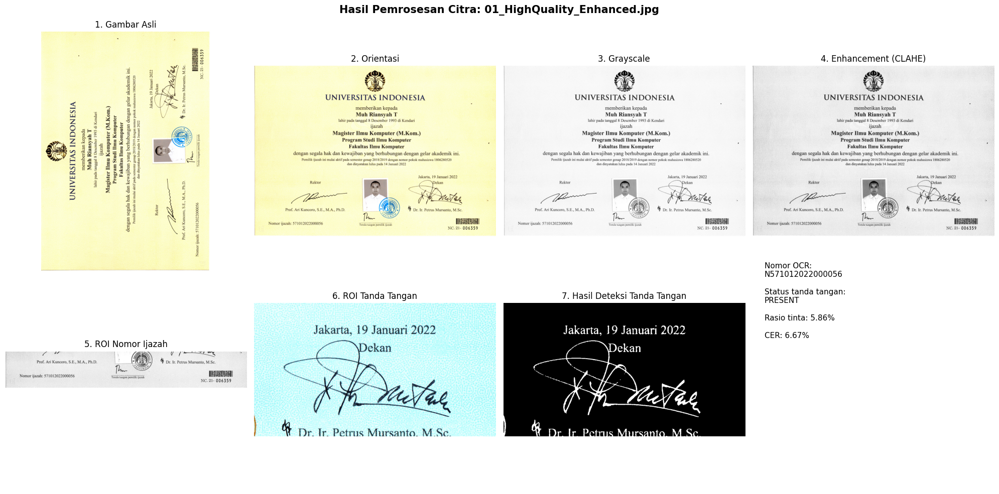


Nama file       : 02_LowContrast.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 5.88%
CER             : 6.67%


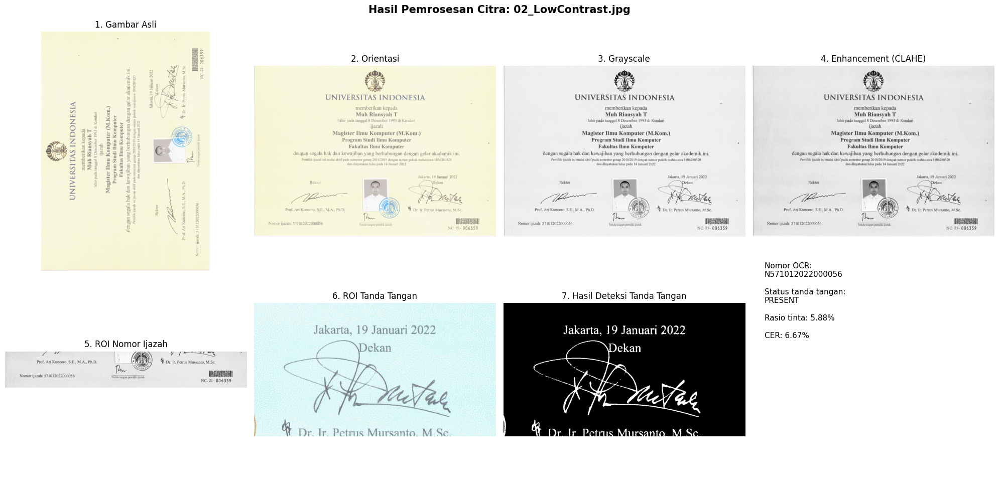


Nama file       : 03_Blurred.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 8.93%
CER             : 6.67%


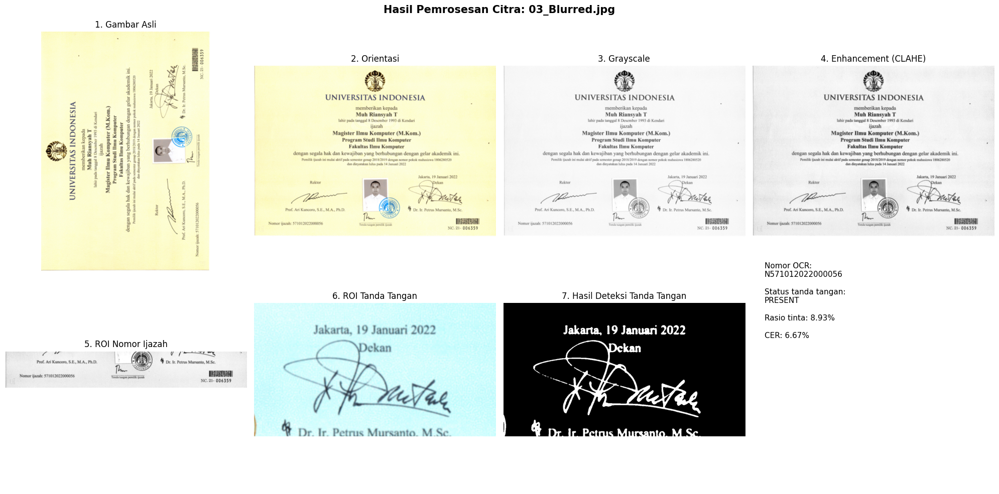


Nama file       : 04_HighNoise.jpg
Nomor ijazah    : Tidak terbaca
Status tanda tangan: PRESENT
Rasio tinta     : 5.73%
CER             : Tidak dapat dihitung


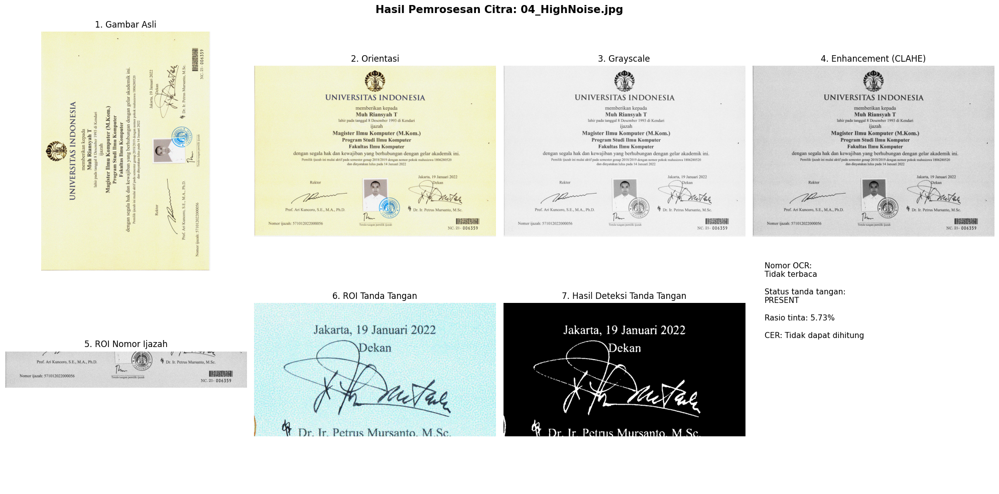


Nama file       : 05_LowResolution_Upsampled.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 6.64%
CER             : 6.67%


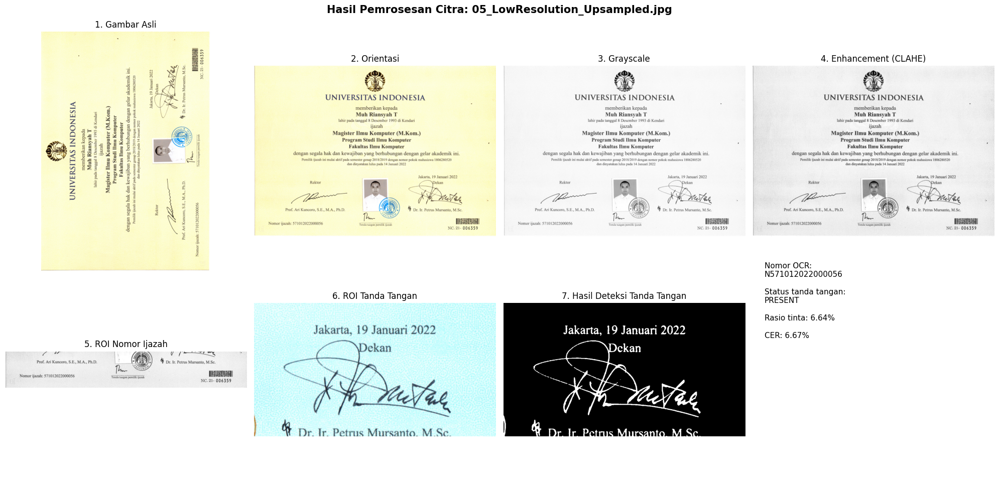


Nama file       : 06_Faded_Underexposed.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 5.95%
CER             : 6.67%


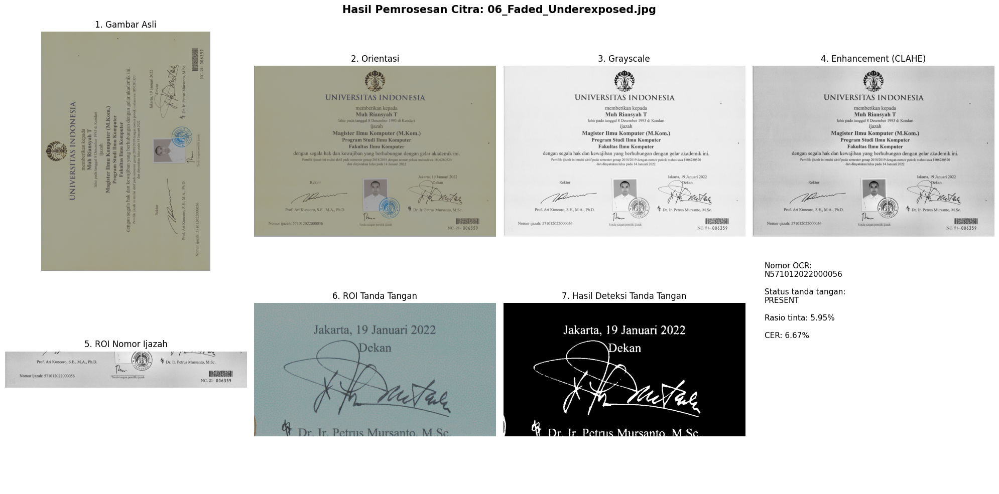


Nama file       : 07_ColorShift_WarmTint.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 5.89%
CER             : 6.67%


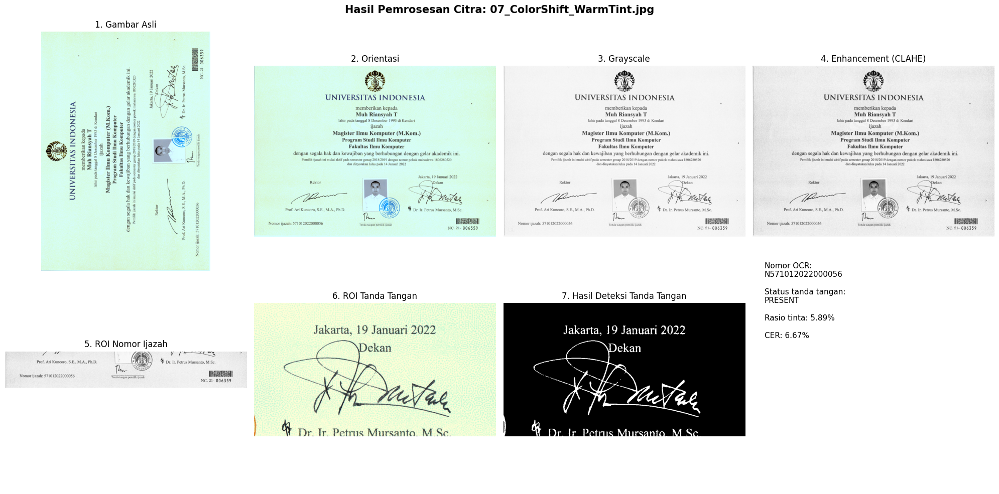


Nama file       : 08_JPEGCompression_Artifacts.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 5.98%
CER             : 6.67%


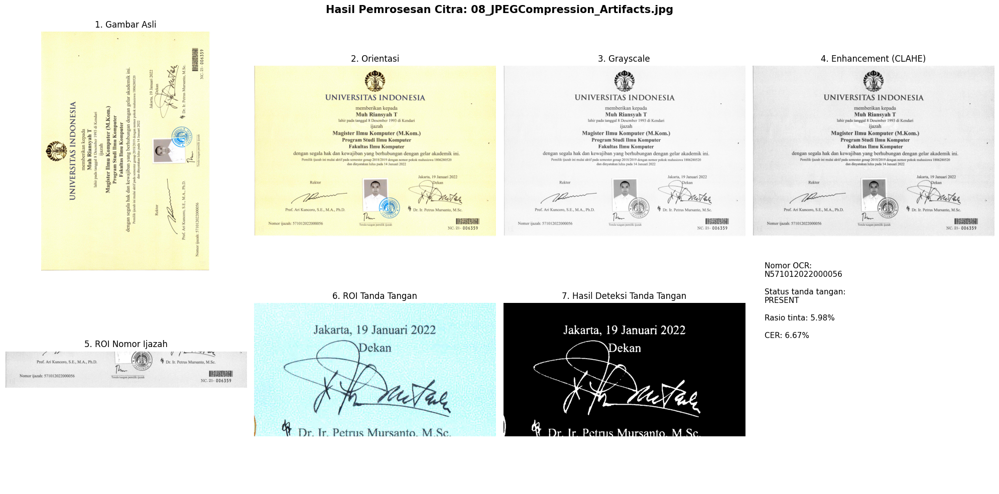


Nama file       : 09_CombinedDegradation.jpg
Nomor ijazah    : N571012022000056
Status tanda tangan: PRESENT
Rasio tinta     : 6.44%
CER             : 6.67%


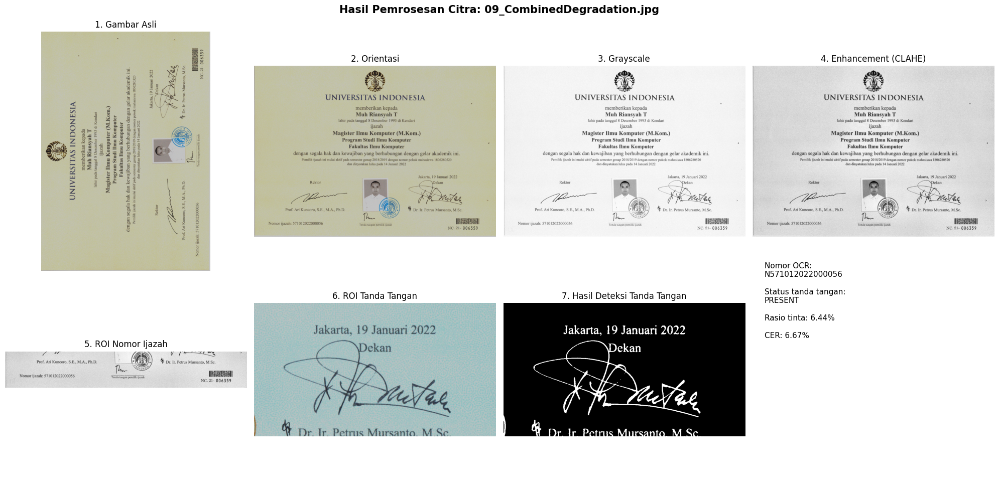


RINGKASAN SELURUH HASIL


,Nama File,Nomor OCR,Status Tanda Tangan,Rasio Tinta (%),CER (%),Sumber OCR
0,01_HighQuality_Enhanced.jpg,N571012022000056,PRESENT,5.8611,6.67,ROI nomor
1,02_LowContrast.jpg,N571012022000056,PRESENT,5.8839,6.67,ROI nomor
2,03_Blurred.jpg,N571012022000056,PRESENT,8.9279,6.67,ROI nomor
3,04_HighNoise.jpg,,PRESENT,5.7287,NaN,ROI nomor
4,05_LowResolution_Upsampled.jpg,N571012022000056,PRESENT,6.6385,6.67,ROI nomor
5,06_Faded_Underexposed.jpg,N571012022000056,PRESENT,5.9450,6.67,ROI nomor
6,07_ColorShift_WarmTint.jpg,N571012022000056,PRESENT,5.8946,6.67,ROI nomor
7,08_JPEGCompression_Artifacts.jpg,N571012022000056,PRESENT,5.9848,6.67,ROI nomor
8,09_CombinedDegradation.jpg,N571012022000056,PRESENT,6.4371,6.67,ROI nomor


In [3]:

# CELL 3 — Memproses semua gambar dan menampilkan seluruh hasilnya

results = []

image_paths = sorted(
    list(DATA_DIR.glob("*.jpg")) +
    list(DATA_DIR.glob("*.jpeg")) +
    list(DATA_DIR.glob("*.png")) +
    list(DATA_DIR.glob("*.bmp"))
)

if not image_paths:
    print(f"Tidak ada gambar ditemukan di folder: {DATA_DIR}")

else:
    print(f"Jumlah gambar ditemukan: {len(image_paths)}")

    for image_path in image_paths:
        result = process_ijazah(
            image_path,
            enhancement_method="clahe"
        )
        results.append(result)

        print("\n" + "=" * 80)
        print(f"Nama file       : {result['file_name']}")
        print(f"Nomor ijazah    : {result['number'] or 'Tidak terbaca'}")
        print(f"Status tanda tangan: {result['signature_status']}")
        print(f"Rasio tinta     : {result['ink_ratio_percent']:.2f}%")

        if result["cer_percent"] is not None:
            print(f"CER             : {result['cer_percent']:.2f}%")
        else:
            print("CER             : Tidak dapat dihitung")

        if result["ocr_error"]:
            print(f"Pesan OCR       : {result['ocr_error']}")

        # Tampilkan semua gambar hasil pemrosesan
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))
        fig.suptitle(
            f"Hasil Pemrosesan Citra: {result['file_name']}",
            fontsize=15,
            fontweight="bold"
        )

        # 1. Gambar asli
        original_rgb = cv2.cvtColor(
            result["original_bgr"], cv2.COLOR_BGR2RGB
        )
        axes[0, 0].imshow(original_rgb)
        axes[0, 0].set_title("1. Gambar Asli")

        # 2. Gambar setelah orientasi
        oriented_rgb = cv2.cvtColor(
            result["oriented_bgr"], cv2.COLOR_BGR2RGB
        )
        axes[0, 1].imshow(oriented_rgb)
        axes[0, 1].set_title("2. Orientasi")

        # 3. Grayscale
        gray_image = cv2.cvtColor(
            result["oriented_bgr"], cv2.COLOR_BGR2GRAY
        )
        axes[0, 2].imshow(gray_image, cmap="gray")
        axes[0, 2].set_title("3. Grayscale")

        # 4. Hasil enhancement
        axes[0, 3].imshow(
            result["enhanced_page"], cmap="gray"
        )
        axes[0, 3].set_title("4. Enhancement (CLAHE)")

        # 5. ROI nomor ijazah
        axes[1, 0].imshow(
            result["number_roi"], cmap="gray"
        )
        axes[1, 0].set_title("5. ROI Nomor Ijazah")

        # 6. ROI tanda tangan
        axes[1, 1].imshow(
            result["signature_roi"], cmap="gray"
        )
        axes[1, 1].set_title("6. ROI Tanda Tangan")

        # 7. Hasil thresholding dan morfologi tanda tangan
        axes[1, 2].imshow(
            result["signature_mask"], cmap="gray"
        )
        axes[1, 2].set_title("7. Hasil Deteksi Tanda Tangan")

        # 8. Ringkasan hasil
        axes[1, 3].axis("off")
        summary = (
            f"Nomor OCR:\n{result['number'] or 'Tidak terbaca'}\n\n"
            f"Status tanda tangan:\n{result['signature_status']}\n\n"
            f"Rasio tinta: {result['ink_ratio_percent']:.2f}%\n\n"
            f"CER: "
            f"{result['cer_percent']:.2f}%"
            if result["cer_percent"] is not None
            else (
                f"Nomor OCR:\n{result['number'] or 'Tidak terbaca'}\n\n"
                f"Status tanda tangan:\n{result['signature_status']}\n\n"
                f"Rasio tinta: {result['ink_ratio_percent']:.2f}%\n\n"
                "CER: Tidak dapat dihitung"
            )
        )
        axes[1, 3].text(
            0.05, 0.95, summary,
            fontsize=11,
            verticalalignment="top",
            wrap=True
        )

        # Hilangkan angka sumbu agar gambar lebih jelas
        for ax in axes.flat:
            ax.axis("off")

        plt.tight_layout()
        plt.show()

    # Tabel ringkasan semua gambar
    df_results = pd.DataFrame([
        {
            "Nama File": r["file_name"],
            "Nomor OCR": r["number"],
            "Status Tanda Tangan": r["signature_status"],
            "Rasio Tinta (%)": r["ink_ratio_percent"],
            "CER (%)": r["cer_percent"],
            "Sumber OCR": r["ocr_source"]
        }
        for r in results
    ])

    print("\nRINGKASAN SELURUH HASIL")
    display(df_results)

## Evaluasi Enhancement Berdasarkan CER

Cell evaluasi membandingkan OCR RAW, sharpen, Otsu threshold, dan CLAHE pada sembilan gambar dengan ground truth 571012022000056. CER untuk hasil yang tidak terbaca ditandai NaN dan tidak disertakan dalam rata-rata metode. Baca tabel hasil aktual di bawah; metode dengan rata-rata CER terendah menjadi yang terbaik untuk dataset ini.

In [4]:
# CELL 4 — Evaluasi metode enhancement berdasarkan CER

evaluation_rows = []

for image_path in image_files:
    img_bgr = cv2.imread(str(image_path))

    if img_bgr is None:
        raise ValueError(
            f"Gambar tidak dapat dibaca: {image_path}"
        )

    # Orientasi dan grayscale
    oriented = orient_page(img_bgr)
    gray = cv2.cvtColor(oriented, cv2.COLOR_BGR2GRAY)

    # Uji seluruh metode enhancement
    for method in ENHANCEMENT_METHODS:
        try:
            number, source, _, _ = read_number(
                gray,
                method
            )

            # Nomor kosong tidak dianggap sebagai hasil OCR valid
            if number:
                cer = calculate_cer(
                    GROUND_TRUTH_NUMBER,
                    number
                )
            else:
                cer = np.nan

            evaluation_rows.append({
                "Gambar": image_path.name,
                "Enhancement": method.upper(),
                "Nomor OCR": number or "TIDAK TERBACA",
                "Sumber OCR": source,
                "CER (%)": round(cer, 2)
                if not np.isnan(cer)
                else np.nan
            })

        except pytesseract.TesseractNotFoundError:
            evaluation_rows.append({
                "Gambar": image_path.name,
                "Enhancement": method.upper(),
                "Nomor OCR": "OCR TIDAK TERSEDIA",
                "Sumber OCR": "-",
                "CER (%)": np.nan
            })

# Tampilkan hasil setiap gambar dan metode
evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df)

# Hitung rata-rata CER masing-masing metode
cer_summary = (
    evaluation_df
    .groupby("Enhancement", as_index=False)["CER (%)"]
    .mean()
    .sort_values("CER (%)", na_position="last")
)

print("Rata-rata CER setiap metode (lebih rendah lebih baik):")
display(cer_summary)

# Tentukan metode terbaik berdasarkan hasil pengujian
valid_summary = cer_summary.dropna(subset=["CER (%)"])

if valid_summary.empty:
    print(
        "Metode terbaik belum dapat ditentukan. "
        "Pastikan Tesseract berjalan dan nomor rujukan benar."
    )
else:
    lowest_cer = valid_summary["CER (%)"].min()

    best_methods = valid_summary.loc[
        np.isclose(
            valid_summary["CER (%)"],
            lowest_cer
        ),
        "Enhancement"
    ].tolist()

    print(f"CER terendah: {lowest_cer:.2f}%")
    print("Metode dengan CER terendah:", ", ".join(best_methods))

    if len(best_methods) > 1:
        print(
            "Hasilnya seri. Pilih metode yang paling sederhana "
            "atau paling sesuai setelah memeriksa hasil OCR."
        )
    else:
        print(
            "Metode dengan rata-rata CER terendah pada dataset ini:",
            best_methods[0]
        )

,Gambar,Enhancement,Nomor OCR,Sumber OCR,CER (%)
0,01_HighQuality_Enhanced.jpg,RAW,N571012022000056,ROI nomor,6.67
1,01_HighQuality_Enhanced.jpg,SHARPEN,NJ5710120220000563,ROI nomor,20.00
2,01_HighQuality_Enhanced.jpg,THRESHOLD,N571012022000056,ROI nomor,6.67
3,01_HighQuality_Enhanced.jpg,CLAHE,N571012022000056,ROI nomor,6.67
4,02_LowContrast.jpg,RAW,571012022000056,ROI nomor,0.00
5,02_LowContrast.jpg,SHARPEN,NJ571012022000056,ROI nomor,13.33
6,02_LowContrast.jpg,THRESHOLD,N571012022000056,ROI nomor,6.67
7,02_LowContrast.jpg,CLAHE,N571012022000056,ROI nomor,6.67
8,03_Blurred.jpg,RAW,NJ571012022000056,ROI nomor,13.33
9,03_Blurred.jpg,SHARPEN,N571012022000056,ROI nomor,6.67


Rata-rata CER setiap metode (lebih rendah lebih baik):


,Enhancement,CER (%)
1,RAW,6.668889
0,CLAHE,6.670000
3,THRESHOLD,6.670000
2,SHARPEN,11.112222


CER terendah: 6.67%
Metode dengan CER terendah: RAW
Metode dengan rata-rata CER terendah pada dataset ini: RAW


## Interpretasi dan Kesimpulan

CER dihitung dari jarak Levenshtein (substitusi, penghapusan, dan penyisipan karakter) dibagi jumlah karakter ground truth, dalam persen. CER 0% menandakan kecocokan sempurna, sedangkan nilai lebih tinggi menandakan lebih banyak kesalahan.

Pada keluaran evaluasi tersimpan, rata-rata CER adalah RAW 6.6689%, CLAHE 6.6700%, Otsu threshold 6.6700%, dan sharpen 11.1122%. Dengan demikian RAW memperoleh rata-rata terendah, tetapi selisih terhadap CLAHE dan Otsu sangat kecil. Sharpen menghasilkan rata-rata kesalahan lebih tinggi pada dataset ini. Hasil per gambar menunjukkan RAW tidak selalu terbaik untuk setiap sampel, dan citra high-noise dengan CLAHE tidak terbaca.

Pada keluaran prototype, delapan dari sembilan gambar terbaca sebagai N571012022000056 (CER 6.67%); 04_HighNoise.jpg tidak terbaca dan CER-nya tidak dihitung. Semua gambar diberi status tanda tangan PRESENT oleh aturan rasio tinta 1.5%. Karena label status itu berasal dari threshold heuristik, hasil tersebut tidak membuktikan tanda tangan asli atau keabsahan ijazah. Kesimpulan berlaku untuk citra, ROI, Tesseract, dan nomor rujukan yang digunakan di notebook ini.